# Email Spam Detection with Machine Learning
**Natural Language Processing · Binary Text Classification**

**Objective:** build a classifier that separates spam from legitimate (ham) messages.

**Dataset:** UCI Machine Learning Repository spam collection, 5,572 labelled text messages. The same preprocessing and modelling approach applies directly to email text.

**Workflow:** data loading and class distribution, text preprocessing, TF-IDF feature extraction, stratified train/test split, model training (Multinomial Naive Bayes, Logistic Regression, Linear SVM), evaluation, discussion, and word clouds.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the data

In [2]:
# Accepts the Kaggle file (spam.csv with columns v1, v2) or the cleaned spam.csv
# shipped in this folder (columns label, message).
df = pd.read_csv("spam.csv", encoding="latin-1")

if {"v1", "v2"}.issubset(df.columns):          # Kaggle format
    df = df[["v1", "v2"]].rename(columns={"v1": "label", "v2": "message"})
else:                                          # this repo's format
    df = df[["label", "message"]]

df = df.dropna().drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
df.head()

Shape after removing duplicates: (5169, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Class distribution (spam vs. ham)

       count  percent
label                
ham     4516    87.37
spam     653    12.63


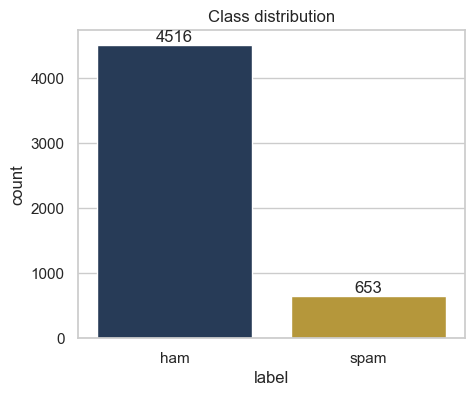

In [3]:
counts = df["label"].value_counts()
percent = df["label"].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": counts, "percent": percent}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="label", hue="label", order=["ham", "spam"], palette=["#2A9D8F", "#E9C46A"], legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Class distribution")
plt.show()

The data is **imbalanced**: ham messages far outnumber spam. Accuracy alone would therefore be misleading (a model that predicts "ham" every time would still score high), so precision, recall and F1 for the spam class are reported as well.

## 3. Text preprocessing
Lowercase → remove URLs/numbers/punctuation → remove stopwords.

In [4]:
STOPWORDS = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = text.lower()                              # lowercase
    text = re.sub(r"&\w+;", " ", text)               # HTML codes such as &lt; &gt; &amp;
    text = re.sub(r"http\S+|www\S+", " ", text)      # URLs
    text = re.sub(r"[^a-z\s]", " ", text)            # punctuation and digits
    tokens = [w for w in text.split() if w not in STOPWORDS and len(w) > 1]
    return " ".join(tokens)

df["clean"] = df["message"].apply(clean_text)
df[["message", "clean"]].head()

,message,clean
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis great world...
1,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,dun say early hor say
4,"Nah I don't think he goes to usf, he lives aro...",nah don think goes usf lives


## 4. Feature extraction: TF-IDF

**What TF-IDF measures.** TF-IDF (*Term Frequency – Inverse Document Frequency*) scores how important a word is to a message relative to the whole collection.

- **TF** is how often the word appears in that message.
- **IDF** down-weights words that appear in many messages (for example "get" or "go") and boosts words that are rare across the collection.

A word therefore gets a high score when it is frequent in one message but uncommon overall. Words such as "free", "claim" and "prize" stand out in spam, while everyday words carry little weight.

In [5]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean"], (df["label"] == "spam").astype(int),
    test_size=0.2, random_state=RANDOM_STATE, stratify=df["label"]
)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train = tfidf.fit_transform(X_train_text)   # fit on training data only
X_test = tfidf.transform(X_test_text)

print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
print("Vocabulary size:", len(tfidf.vocabulary_))

Train size: 4135 | Test size: 1034
Vocabulary size: 5202


The split is **stratified**, so spam and ham keep the same proportions in the training and test sets. The vectorizer is fitted on the training data only to avoid data leakage.

## 5. Train the classifiers

In [6]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
}

results, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial Naive Bayes,0.9816,0.9590,0.8931,0.9249
Logistic Regression,0.9739,0.8824,0.9160,0.8989
Linear SVM,0.9816,0.9308,0.9237,0.9272


## 6. Evaluation

In [7]:
for name, pred in predictions.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=4))

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham     0.9846    0.9945    0.9895       903
        spam     0.9590    0.8931    0.9249       131

    accuracy                         0.9816      1034
   macro avg     0.9718    0.9438    0.9572      1034
weighted avg     0.9814    0.9816    0.9813      1034

Logistic Regression
              precision    recall  f1-score   support

         ham     0.9878    0.9823    0.9850       903
        spam     0.8824    0.9160    0.8989       131

    accuracy                         0.9739      1034
   macro avg     0.9351    0.9492    0.9419      1034
weighted avg     0.9744    0.9739    0.9741      1034

Linear SVM
              precision    recall  f1-score   support

         ham     0.9889    0.9900    0.9895       903
        spam     0.9308    0.9237    0.9272       131

    accuracy                         0.9816      1034
   macro avg     0.9599    0.9568    0.9583      1034
weighted avg     0.

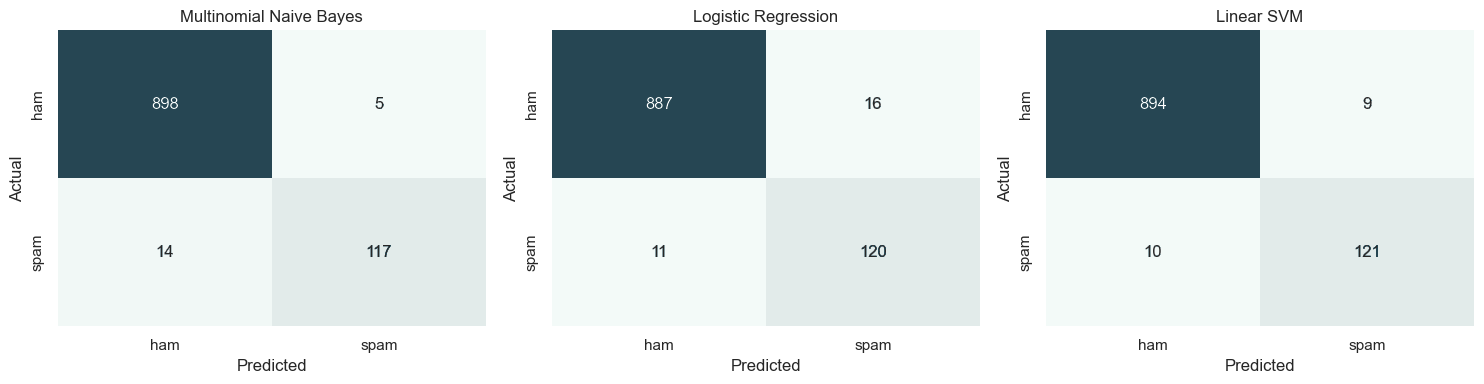

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=sns.light_palette("#2A9D8F", as_cmap=True), cbar=False, ax=ax,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

Best model by F1-score: Linear SVM


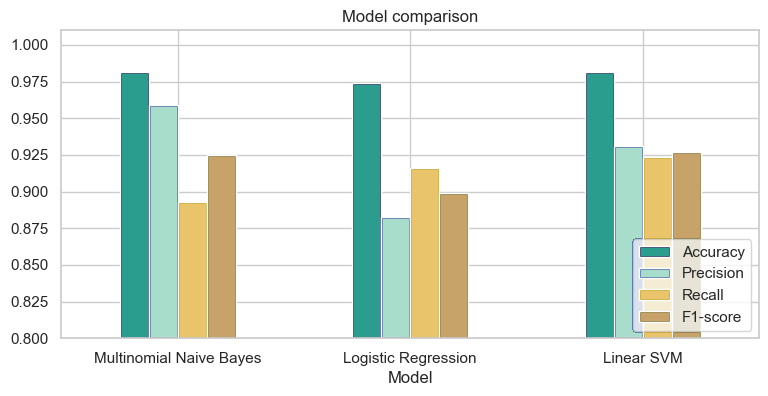

In [9]:
best = results_df["F1-score"].idxmax()
print(f"Best model by F1-score: {best}")
results_df.plot(kind="bar", figsize=(9, 4), rot=0, ylim=(0.8, 1.01),
                color=["#2A9D8F", "#A8DCCB", "#E9C46A", "#C7A36A"])
plt.title("Model comparison")
plt.legend(loc="lower right")
plt.show()

## 7. Discussion: why is recall important for spam detection?

**Recall** is the share of actual spam messages the model catches: `TP / (TP + FN)`. A low recall means spam slips through into the inbox. That exposes users to phishing, scams and malware, and it defeats the purpose of a spam filter.

At the same time, **precision** matters because a false positive (a legitimate message sent to spam) can hide something important. Real systems therefore balance the two, and the F1-score summarises that balance. Because spam is the minority class here, recall on the spam class is a more honest measure of filter quality than overall accuracy.

## 8. Bonus: word clouds

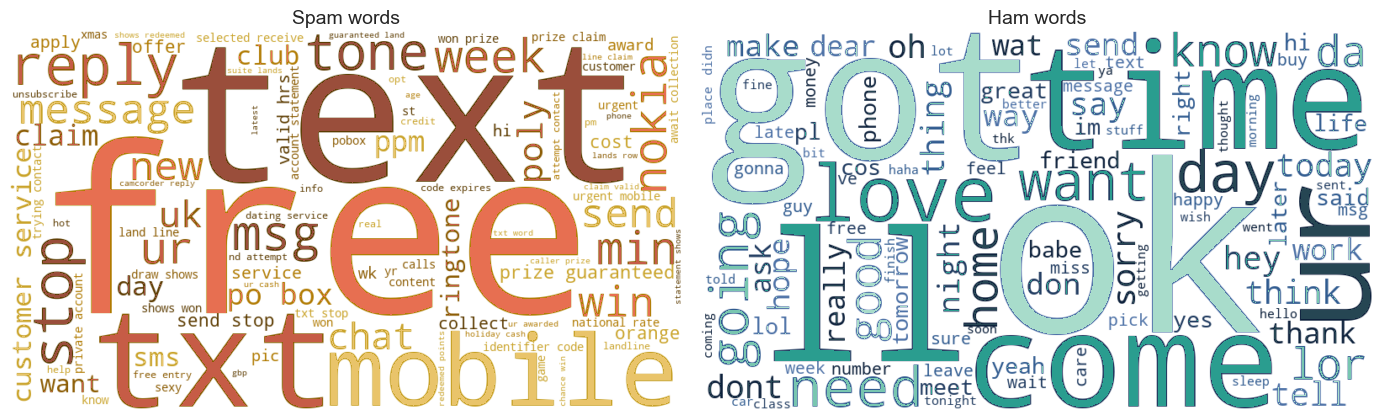

In [10]:
from matplotlib.colors import ListedColormap
from wordcloud import WordCloud

spam_text = " ".join(df.loc[df["label"] == "spam", "clean"])
ham_text = " ".join(df.loc[df["label"] == "ham", "clean"])

spam_colors = ListedColormap(["#9A4E3B", "#C65C46", "#E76F51", "#F2A18E"])
ham_colors = ListedColormap(["#264653", "#2A9D8F", "#78C6B0", "#A8DCCB"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, text, title, cmap in [(axes[0], spam_text, "Spam words", spam_colors),
                              (axes[1], ham_text, "Ham words", ham_colors)]:
    wc = WordCloud(width=800, height=450, background_color="white",
                   colormap=cmap, max_words=100).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title, fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Predictions on new messages

In [11]:
final_model = models["Multinomial Naive Bayes"]

def predict_message(text):
    vec = tfidf.transform([clean_text(text)])
    return "SPAM" if final_model.predict(vec)[0] == 1 else "HAM"

samples = [
    "Congratulations! You have won a free prize. Call now to claim your reward.",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT: your account is suspended. Click the link to verify and claim 500 cash.",
    "Can you send me the notes from today's class?",
]
for s in samples:
    print(f"{predict_message(s):5} | {s}")

SPAM  | Congratulations! You have won a free prize. Call now to claim your reward.
HAM   | Hey, are we still meeting for lunch tomorrow?
SPAM  | URGENT: your account is suspended. Click the link to verify and claim 500 cash.
HAM   | Can you send me the notes from today's class?


## 10. Conclusion

- The dataset is imbalanced, so precision, recall and F1-score were reported alongside accuracy.
- TF-IDF features with Multinomial Naive Bayes, Logistic Regression and Linear SVM all separate spam from ham with high accuracy.
- Recall on the spam class is the key measure of how much spam a filter lets through.
- Future improvements: hyperparameter tuning with cross-validation, stemming or lemmatization, and evaluation on a full-length email corpus.